<a href="https://colab.research.google.com/github/projetothermocmm-a11y/python-code/blob/main/thermo_analise_completa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Thermo — Influência das terras-raras sobre a Tc e triagem de candidatos sustentáveis

A análise estatística vem **antes** do aprendizado de máquina. O notebook responde a duas perguntas:

1. Qual é o efeito da presença de terras-raras sobre a temperatura crítica (Tc), comparando materiais da mesma família?
2. Quais propriedades derivadas da composição química mais se relacionam com a Tc?

Depois, um modelo XGBoost (avaliado em sistemas químicos que não viu no treino) e o
Therm° Sustainability Score (TSS) são usados para triar candidatos sem terras-raras e de baixa toxicidade.

**Arquivos necessários na pasta de trabalho:** `train.csv` e `unique_m.csv` (SuperCon processada por
Hamidieh, 2018) e `lca_nuss_eckelman_2014.csv` (pegada de carbono por elemento, Nuss e Eckelman, 2014).
Figuras e tabelas são salvas em `reports/`.

In [ ]:
# Conecta o Google Drive e trabalha dentro da pasta do projeto
import os
from google.colab import drive
drive.mount('/content/drive')
PASTA = '/content/drive/MyDrive/projeto_therm_febrace'   # ajuste se a pasta tiver outro nome
os.makedirs(PASTA, exist_ok=True)
os.chdir(PASTA)
os.makedirs('reports', exist_ok=True)
print('Pasta de trabalho:', os.getcwd())
print('Arquivos:', os.listdir('.'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta de trabalho: /content/drive/MyDrive/projeto_therm_febrace
Arquivos: ['train.csv', 'unique_m.csv', 'lca_nuss_eckelman_2014.csv', 'reports']


In [ ]:
import os
import re
import warnings
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold, GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import shap

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
SEED = 42
RNG = np.random.default_rng(SEED)
os.makedirs('reports', exist_ok=True)

## Etapa 1 — Preparação dos dados

Decisões, todas determinísticas:

- **Variável terras-raras:** 1 se o composto contém qualquer terra-rara, 0 se não.
- **Família:** regras simples pela composição. *Cuprato* = contém Cu e O. *Ferro* = contém Fe e um ânion da família do ferro (As, P, Se, Te ou S), sem ser cuprato. *Outros* = o restante. É uma aproximação, e isso entra nas limitações.
- **Deduplicação por composição:** a SuperCon tem o mesmo composto medido várias vezes, às vezes com a fórmula escrita de formas diferentes (ex.: `Ba2Ca3Cu5O12` e `Cu5Ba2Ca3O12`). Agrupamos pela composição normalizada (fração de cada elemento) e ficamos com a Tc mediana.
- **Sistema químico:** o conjunto de elementos, sem as proporções. Usado para controlar a dependência entre compostos parecidos.
- **Registros sinalizados** (mantidos na análise estatística, excluídos da triagem): cupratos com menos oxigênio que cobre (fórmula registrada sem o índice do O) e hidretos binários (Tc alta medida só sob pressões extremas).

In [ ]:
train = pd.read_csv('train.csv')
unique_m = pd.read_csv('unique_m.csv')
assert len(train) == len(unique_m)

elem_cols = [c for c in unique_m.columns if c not in ('critical_temp', 'material')]
comp = unique_m[elem_cols]

TERRAS_RARAS = ['Sc', 'Y', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd',
                'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']

# Eletronegatividade de Pauling (não existe na base de Hamidieh; calculada a partir da composição)
ELETRONEG = {
    'H':2.20,'Li':0.98,'Be':1.57,'B':2.04,'C':2.55,'N':3.04,'O':3.44,'F':3.98,
    'Na':0.93,'Mg':1.31,'Al':1.61,'Si':1.90,'P':2.19,'S':2.58,'Cl':3.16,
    'K':0.82,'Ca':1.00,'Sc':1.36,'Ti':1.54,'V':1.63,'Cr':1.66,'Mn':1.55,'Fe':1.83,
    'Co':1.88,'Ni':1.91,'Cu':1.90,'Zn':1.65,'Ga':1.81,'Ge':2.01,'As':2.18,'Se':2.55,'Br':2.96,
    'Rb':0.82,'Sr':0.95,'Y':1.22,'Zr':1.33,'Nb':1.60,'Mo':2.16,'Tc':1.90,'Ru':2.20,
    'Rh':2.28,'Pd':2.20,'Ag':1.93,'Cd':1.69,'In':1.78,'Sn':1.96,'Sb':2.05,'Te':2.10,'I':2.66,
    'Cs':0.79,'Ba':0.89,'La':1.10,'Ce':1.12,'Pr':1.13,'Nd':1.14,'Pm':1.13,'Sm':1.17,
    'Eu':1.20,'Gd':1.20,'Tb':1.10,'Dy':1.22,'Ho':1.23,'Er':1.24,'Tm':1.25,'Yb':1.10,'Lu':1.27,
    'Hf':1.30,'Ta':1.50,'W':2.36,'Re':1.90,'Os':2.20,'Ir':2.20,'Pt':2.28,'Au':2.54,
    'Hg':2.00,'Tl':1.62,'Pb':2.33,'Bi':2.02,'Po':2.00,'At':2.20
}

df = train.copy()
df['material'] = unique_m['material']
df['tem_terra_rara'] = (comp[TERRAS_RARAS] > 0).any(axis=1).astype(int)

# Média ponderada da eletronegatividade (só sobre elementos com valor conhecido)
en = pd.Series(ELETRONEG).reindex(elem_cols)
mask_en = en.notna().values
df['eletroneg_pond'] = (comp.values[:, mask_en] @ en.values[mask_en]) / comp.values[:, mask_en].sum(axis=1)

tem = lambda *els: (comp[list(els)] > 0).any(axis=1)
cuprato = tem('Cu') & tem('O')
ferro = tem('Fe') & tem('As', 'P', 'Se', 'Te', 'S') & ~cuprato
df['familia'] = np.select([cuprato, ferro], ['Cuprato', 'Ferro'], default='Outros')

df['sistema'] = comp.gt(0).apply(lambda r: '-'.join(sorted(r.index[r])), axis=1)

# Registros a sinalizar
n_elem = (comp > 0).sum(axis=1)
df['oxigenio_incompleto'] = cuprato & (comp['O'] < comp['Cu'])     # ex.: 'Ba2Ca2Cu3O'
df['hidreto_binario'] = (comp['H'] > 0) & (n_elem == 2)            # ex.: H2S (alta pressão)

# Deduplicação por composição normalizada (a mesma composição pode estar escrita de formas diferentes).
# As 81 variáveis de Hamidieh dependem só das proporções, então são idênticas dentro de cada grupo.
fracoes = comp.div(comp.sum(axis=1), axis=0).round(4)
df['_chave'] = pd.util.hash_pandas_object(fracoes, index=False)
agg = {c: 'first' for c in df.columns if c not in ('_chave', 'critical_temp')}
agg['critical_temp'] = 'median'
dados = df.groupby('_chave', as_index=False).agg(agg).drop(columns='_chave')
dados['log10_Tc'] = np.log10(dados['critical_temp'])

# Composição de cada composto deduplicado (mesma ordem de `dados`), usada no TSS e na triagem
primeira_linha = df.reset_index().groupby('_chave')['index'].first()
comp_dados = comp.loc[primeira_linha.values].reset_index(drop=True)

print(f'Registros na base original: {len(df):,}')
print(f'Fórmulas distintas: {df["material"].nunique():,}')
print(f'Compostos únicos (após deduplicação por composição): {len(dados):,}')
print(f'Sistemas químicos distintos: {dados["sistema"].nunique():,}')
print(f'Cupratos com oxigênio incompleto: {int(dados["oxigenio_incompleto"].sum()):,}')
print(f'Hidretos binários: {int(dados["hidreto_binario"].sum()):,}')
assert (dados['material'].values == df.loc[primeira_linha.values, 'material'].values).all()


Registros na base original: 21,263
Fórmulas distintas: 15,542
Compostos únicos (após deduplicação por composição): 15,136
Sistemas químicos distintos: 3,363
Cupratos com oxigênio incompleto: 1,288
Hidretos binários: 21


### Tabela descritiva

In [ ]:
FAMILIAS = ['Cuprato', 'Ferro', 'Outros']
desc = (dados.groupby(['familia', 'tem_terra_rara'])['critical_temp']
        .agg(n='size', mediana='median', media='mean', maximo='max',
             acima_77K=lambda s: (s > 77).mean() * 100)
        .round(1))
desc.index = desc.index.set_levels(['Sem TR', 'Com TR'], level=1)
desc = desc.rename(columns={'acima_77K': '% acima de 77 K'})
print(desc)

                           n  mediana  media  maximo  % acima de 77 K
familia tem_terra_rara                                               
Cuprato Sem TR          1508     87.5   82.2   143.0             61.5
        Com TR          5981     52.5   52.8   128.0             28.0
Ferro   Sem TR           678     15.5   18.0    46.0              0.0
        Com TR           554     23.6   25.0    61.4              0.0
Outros  Sem TR          4689      4.6    7.2   122.5              0.1
        Com TR          1726      3.4    5.0    90.4              0.2


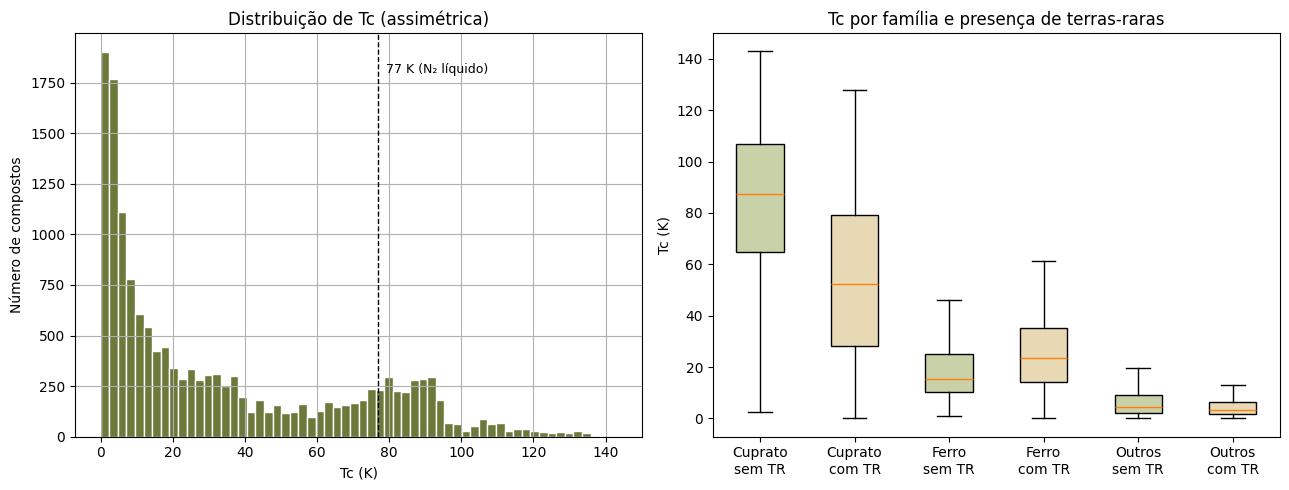

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

dados['critical_temp'].hist(bins=60, ax=axes[0], color='#6b7a3a', edgecolor='white')
axes[0].axvline(77, color='k', ls='--', lw=1)
axes[0].text(79, axes[0].get_ylim()[1] * 0.9, '77 K (N₂ líquido)', fontsize=9)
axes[0].set_xlabel('Tc (K)')
axes[0].set_ylabel('Número de compostos')
axes[0].set_title('Distribuição de Tc (assimétrica)')

grupos, rotulos = [], []
for fam in FAMILIAS:
    for tr, nome in [(0, 'sem TR'), (1, 'com TR')]:
        grupos.append(dados.loc[(dados.familia == fam) & (dados.tem_terra_rara == tr), 'critical_temp'])
        rotulos.append(f'{fam}\n{nome}')
bp = axes[1].boxplot(grupos, showfliers=False, patch_artist=True)
axes[1].set_xticks(range(1, len(rotulos) + 1), rotulos)
for i, caixa in enumerate(bp['boxes']):
    caixa.set_facecolor('#c9d1a8' if i % 2 == 0 else '#e8d9b5')
axes[1].set_ylabel('Tc (K)')
axes[1].set_title('Tc por família e presença de terras-raras')
plt.tight_layout()
plt.savefig('reports/fig1_distribuicao_e_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

## Etapa 2 — Terras-raras: comparação dentro de cada família

Para cada família, comparamos a Tc dos compostos com e sem terras-raras:

- **Mann-Whitney U:** testa se um grupo tende a ter Tc maior que o outro, sem supor distribuição normal.
- **Delta de Cliff (δ):** tamanho do efeito, de −1 a +1. Positivo = compostos *com* terras-raras tendem a ter Tc maior. Referência usual: |δ| < 0,15 desprezível; < 0,33 pequeno; < 0,47 médio; ≥ 0,47 grande.
- **Diferença de medianas com IC 95% por bootstrap:** quanto, em kelvin, a Tc mediana muda.
- **Teste exato de Fisher:** compara a proporção de compostos acima de 77 K.

Com milhares de compostos, quase toda diferença dá p muito pequeno. Por isso o resultado principal é o **tamanho do efeito**, não o p-valor.

In [ ]:
def delta_cliff(a, b):
    """δ = P(a > b) − P(a < b), calculado a partir da estatística U."""
    u = stats.mannwhitneyu(a, b, alternative='two-sided').statistic
    return 2 * u / (len(a) * len(b)) - 1

def ic_bootstrap_mediana(a, b, n_boot=2000):
    a, b = np.asarray(a), np.asarray(b)
    difs = [np.median(RNG.choice(a, len(a))) - np.median(RNG.choice(b, len(b))) for _ in range(n_boot)]
    return np.percentile(difs, [2.5, 97.5])

def comparar(tabela, rotulo_unidade):
    linhas = []
    for fam in FAMILIAS:
        sub = tabela[tabela.familia == fam]
        com = sub.loc[sub.tem_terra_rara == 1, 'critical_temp'].values
        sem = sub.loc[sub.tem_terra_rara == 0, 'critical_temp'].values
        if min(len(com), len(sem)) < 5:
            continue
        p_mw = stats.mannwhitneyu(com, sem, alternative='two-sided').pvalue
        ic = ic_bootstrap_mediana(com, sem)
        cont = [[(com > 77).sum(), (com <= 77).sum()], [(sem > 77).sum(), (sem <= 77).sum()]]
        p_f = stats.fisher_exact(cont).pvalue
        linhas.append({
            'Família': fam, 'Unidade': rotulo_unidade,
            'n com TR': len(com), 'n sem TR': len(sem),
            'Mediana com TR (K)': np.median(com), 'Mediana sem TR (K)': np.median(sem),
            'Dif. medianas (K)': np.median(com) - np.median(sem),
            'IC95% inf': ic[0], 'IC95% sup': ic[1],
            'δ Cliff': delta_cliff(com, sem), 'p Mann-Whitney': p_mw,
            '% >77K com TR': (com > 77).mean() * 100, '% >77K sem TR': (sem > 77).mean() * 100,
            'p Fisher (>77K)': p_f,
        })
    return pd.DataFrame(linhas)

res_compostos = comparar(dados, 'composto')

# Análise de sensibilidade: um ponto por sistema químico (Tc mediana do sistema),
# o que reduz o peso de famílias com muitas variantes de dopagem.
por_sistema = dados.groupby('sistema', as_index=False).agg(
    critical_temp=('critical_temp', 'median'), familia=('familia', 'first'),
    tem_terra_rara=('tem_terra_rara', 'first'))
res_sistemas = comparar(por_sistema, 'sistema químico')

res_tr = pd.concat([res_compostos, res_sistemas], ignore_index=True)
print(res_tr.round({'Mediana com TR (K)': 1, 'Mediana sem TR (K)': 1, 'Dif. medianas (K)': 1,
                    'IC95% inf': 1, 'IC95% sup': 1, 'δ Cliff': 3, '% >77K com TR': 1,
                    '% >77K sem TR': 1}).to_string(index=False))

Família         Unidade  n com TR  n sem TR  Mediana com TR (K)  Mediana sem TR (K)  Dif. medianas (K)  IC95% inf  IC95% sup  δ Cliff  p Mann-Whitney  % >77K com TR  % >77K sem TR  p Fisher (>77K)
Cuprato        composto      5981      1508                52.5                87.5              -35.0      -38.0      -32.0   -0.516   8.172836e-211           28.0           61.5    2.328342e-126
  Ferro        composto       554       678                23.6                15.5                8.0        6.3       10.0    0.289    2.497363e-18            0.0            0.0     1.000000e+00
 Outros        composto      1726      4689                 3.4                 4.6               -1.2       -1.5       -1.0   -0.174    1.266260e-26            0.2            0.1     5.006898e-01
Cuprato sistema químico       756       228                50.0                86.0              -36.0      -43.6      -28.1   -0.518    1.667148e-32           24.9           58.3     4.593746e-20
  Ferro sistema

### Cupratos sem mercúrio, tálio e chumbo

A vantagem dos cupratos sem terras-raras pode vir, em boa parte, das famílias de Hg, Tl e Pb, que são altamente tóxicas.
Aqui a comparação é refeita **só com cupratos que não contêm esses elementos**. Se a vantagem se mantiver,
existe Tc alta sem terras-raras e sem tóxicos; se desaparecer, o desafio real é substituir esses elementos.

In [ ]:
TOXICOS_CUPRATOS = ['Hg', 'Tl', 'Pb']
dados['contem_Hg_Tl_Pb'] = (comp_dados[TOXICOS_CUPRATOS] > 0).any(axis=1).values

cupratos = dados[dados.familia == 'Cuprato']
print('Cupratos sem terras-raras: '
      f'{int((cupratos.tem_terra_rara == 0).sum()):,} no total, '
      f'{int(((cupratos.tem_terra_rara == 0) & cupratos.contem_Hg_Tl_Pb).sum()):,} contêm Hg, Tl ou Pb')

limpos = dados[~dados.contem_Hg_Tl_Pb].copy()
por_sistema_limpos = limpos.groupby('sistema', as_index=False).agg(
    critical_temp=('critical_temp', 'median'), familia=('familia', 'first'),
    tem_terra_rara=('tem_terra_rara', 'first'))
res_limpos = pd.concat([comparar(limpos, 'composto'), comparar(por_sistema_limpos, 'sistema químico')],
                       ignore_index=True)
res_limpos = res_limpos[res_limpos['Família'] == 'Cuprato']
print(res_limpos.round({'Mediana com TR (K)': 1, 'Mediana sem TR (K)': 1, 'Dif. medianas (K)': 1,
                        'IC95% inf': 1, 'IC95% sup': 1, 'δ Cliff': 3, '% >77K com TR': 1,
                        '% >77K sem TR': 1}).to_string(index=False))

print('\nDez cupratos sem terras-raras e sem Hg, Tl ou Pb com maior Tc (sem fórmulas de oxigênio incompleto):')
print(limpos[(limpos.familia == 'Cuprato') & (limpos.tem_terra_rara == 0) & ~limpos.oxigenio_incompleto]
      .nlargest(10, 'critical_temp')[['material', 'critical_temp']].to_string(index=False))

Cupratos sem terras-raras: 1,508 no total, 910 contêm Hg, Tl ou Pb
Família         Unidade  n com TR  n sem TR  Mediana com TR (K)  Mediana sem TR (K)  Dif. medianas (K)  IC95% inf  IC95% sup  δ Cliff  p Mann-Whitney  % >77K com TR  % >77K sem TR  p Fisher (>77K)
Cuprato        composto      5251       598                52.0                75.0              -23.0      -26.0      -21.3   -0.291    1.793220e-31           27.8           45.5     5.605548e-18
Cuprato sistema químico       566        75                45.4                75.0              -29.6      -36.5      -20.5   -0.306    1.670111e-05           22.3           44.0     1.011302e-04

Dez cupratos sem terras-raras e sem Hg, Tl ou Pb com maior Tc (sem fórmulas de oxigênio incompleto):
                  material  critical_temp
                  Cu1Cr1O2          132.0
              Ba2Ca5Cu7O14          120.0
         Ba2Ca2Cu3F0.8O7.2          120.0
B0.6C0.4Sr0.5Ba1.5Ca2Cu3O9          119.0
         Cu1Cr0.95Fe0.05O2    

### Contraexemplos diretos

A pergunta "terras-raras são *necessárias*?" é lógica: basta um contraexemplo para respondê-la.
Abaixo, os compostos **sem** terras-raras com as maiores Tc na própria base.

In [ ]:
contra = (dados[dados.tem_terra_rara == 0]
          .sort_values('critical_temp', ascending=False)
          [['material', 'familia', 'critical_temp', 'hidreto_binario']].head(10))
print(contra.to_string(index=False))
print(f'\nCompostos SEM terras-raras acima de 77 K: {((dados.tem_terra_rara == 0) & (dados.critical_temp > 77)).sum():,}')
print(f'Compostos COM terras-raras acima de 77 K: {((dados.tem_terra_rara == 1) & (dados.critical_temp > 77)).sum():,}')

                      material familia  critical_temp  hidreto_binario
Hg0.66Pb0.34Ba2Ca1.98Cu2.9O8.4 Cuprato          143.0            False
         Tl0.8Hg0.2Ba2Ca2Cu3O9 Cuprato          137.4            False
         Hg0.7Pb0.3Ba2Ca2Cu3O8 Cuprato          136.5            False
     Bi1.8Pb0.2Sb0.1Sr2Ca2Cu2O Cuprato          136.0            False
Hg0.75Ba2.07Ca2.07Cu3.11O8.208 Cuprato          135.8            False
Hg0.75Ba2.07Ca2.07Cu3.11O8.187 Cuprato          135.4            False
               Hg1Ba2Ca2Cu3FO8 Cuprato          135.0            False
             Hg1Ba2Ca2Cu3O8.29 Cuprato          135.0            False
             Hg1Ba2Ca2Cu3O8.27 Cuprato          135.0            False
 Hg0.75Ba2.07Ca2.07Cu3.11O8.15 Cuprato          134.7            False

Compostos SEM terras-raras acima de 77 K: 935
Compostos COM terras-raras acima de 77 K: 1,678


## Etapa 3 — Quais propriedades se relacionam com a Tc?

Escolhemos 10 variáveis com interpretação física clara (médias ponderadas pela proporção de cada elemento), em vez das 81 da base, que são muito redundantes entre si.

Usamos a **correlação de Spearman** (ρ), que capta relações monotônicas sem supor linearidade, separada por família. Os p-valores são corrigidos para comparações múltiplas pelo método de **Benjamini-Hochberg**.

In [ ]:
VARIAVEIS = {
    'number_of_elements': 'Nº de elementos',
    'wtd_mean_atomic_mass': 'Massa atômica',
    'wtd_mean_fie': '1ª energia de ionização',
    'wtd_mean_atomic_radius': 'Raio atômico',
    'wtd_mean_Density': 'Densidade',
    'wtd_mean_ElectronAffinity': 'Afinidade eletrônica',
    'wtd_mean_FusionHeat': 'Calor de fusão',
    'wtd_mean_ThermalConductivity': 'Condutividade térmica',
    'wtd_mean_Valence': 'Valência',
    'eletroneg_pond': 'Eletronegatividade',
}

linhas = []
for fam in ['Todas'] + FAMILIAS:
    sub = dados if fam == 'Todas' else dados[dados.familia == fam]
    for col, nome in VARIAVEIS.items():
        rho, p = stats.spearmanr(sub[col], sub['critical_temp'])
        linhas.append({'Família': fam, 'Variável': nome, 'ρ': rho, 'p': p, 'n': len(sub)})
corr = pd.DataFrame(linhas)
corr['p corrigido (BH)'] = multipletests(corr['p'], method='fdr_bh')[1]

matriz = corr.pivot(index='Variável', columns='Família', values='ρ')[['Todas'] + FAMILIAS]
matriz = matriz.reindex(matriz['Todas'].abs().sort_values(ascending=False).index)
print(matriz.round(2))

Família                  Todas  Cuprato  Ferro  Outros
Variável                                              
Valência                 -0.74    -0.39  -0.25   -0.12
Nº de elementos           0.70     0.14   0.18    0.20
Densidade                -0.56     0.09  -0.23   -0.33
Calor de fusão           -0.50     0.28  -0.10    0.22
1ª energia de ionização   0.43    -0.31   0.06    0.02
Massa atômica            -0.40    -0.00  -0.08   -0.38
Condutividade térmica     0.40     0.40  -0.03   -0.10
Raio atômico             -0.39     0.32  -0.01   -0.15
Eletronegatividade        0.37    -0.34   0.06   -0.04
Afinidade eletrônica      0.10    -0.35  -0.00   -0.16


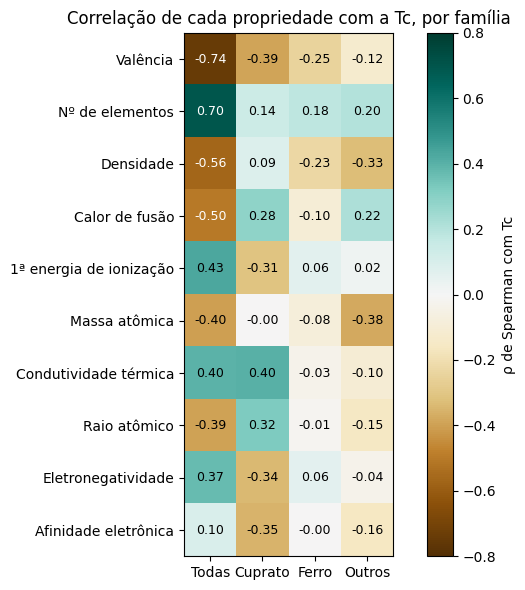

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matriz.values, cmap='BrBG', vmin=-0.8, vmax=0.8)
ax.set_xticks(range(matriz.shape[1]), matriz.columns)
ax.set_yticks(range(matriz.shape[0]), matriz.index)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.5 else 'black')
plt.colorbar(im, label='ρ de Spearman com Tc')
ax.set_title('Correlação de cada propriedade com a Tc, por família')
plt.tight_layout()
plt.savefig('reports/fig2_correlacoes.png', dpi=300, bbox_inches='tight')
plt.show()

## Etapa 4 — Regressão linear múltipla

Modelo: **log₁₀(Tc)** em função das propriedades padronizadas, da presença de terras-raras e da família.

- Usamos log porque a Tc é muito assimétrica.
- As variáveis contínuas são **padronizadas** (média 0, desvio 1), então os coeficientes são comparáveis entre si.
- Antes, checamos a **multicolinearidade (VIF)** e removemos variáveis redundantes (VIF > 10).
- Os erros-padrão são **agrupados por sistema químico** (*cluster-robust*), porque compostos do mesmo sistema não são independentes.

Interpretação do coeficiente de terras-raras: como o Tc está em log₁₀, um coeficiente *b* significa que a Tc é multiplicada por 10^b, mantidas as outras variáveis fixas.

In [ ]:
cols = list(VARIAVEIS)
while True:
    Xv = sm.add_constant((dados[cols] - dados[cols].mean()) / dados[cols].std())
    vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=cols)
    if vif.max() <= 10:
        break
    print(f'Removendo {VARIAVEIS[vif.idxmax()]} (VIF = {vif.max():.1f})')
    cols.remove(vif.idxmax())
print('\nVIF das variáveis mantidas:')
print(vif.rename(VARIAVEIS).round(2).to_string())

Removendo Eletronegatividade (VIF = 14.2)
Removendo Densidade (VIF = 11.3)

VIF das variáveis mantidas:
Nº de elementos            2.00
Massa atômica              2.29
1ª energia de ionização    5.61
Raio atômico               6.24
Afinidade eletrônica       2.31
Calor de fusão             1.88
Condutividade térmica      1.62
Valência                   4.37


In [ ]:
def montar_X(tabela, cols, com_familia=True, com_tr=True):
    X = (tabela[cols] - dados[cols].mean()) / dados[cols].std()
    X = X.rename(columns=VARIAVEIS)
    if com_tr:
        X['Terras-raras (0/1)'] = tabela['tem_terra_rara']
    if com_familia:
        X['Família: Ferro'] = (tabela['familia'] == 'Ferro').astype(int)
        X['Família: Outros'] = (tabela['familia'] == 'Outros').astype(int)
    return sm.add_constant(X)

grupos_sistema = pd.factorize(dados['sistema'])[0]
X = montar_X(dados, cols)
ols = sm.OLS(dados['log10_Tc'], X).fit(cov_type='cluster', cov_kwds={'groups': grupos_sistema})

tab_coef = pd.DataFrame({'coef': ols.params, 'IC95% inf': ols.conf_int()[0],
                         'IC95% sup': ols.conf_int()[1], 'p': ols.pvalues}).drop('const')
tab_coef['fator sobre Tc'] = 10 ** tab_coef['coef']
print(tab_coef.sort_values('coef', key=abs, ascending=False).round(3))
print(f'\nR² = {ols.rsquared:.3f}   |   n = {int(ols.nobs):,} compostos   |   {len(np.unique(grupos_sistema)):,} sistemas')

                          coef  IC95% inf  IC95% sup      p  fator sobre Tc
Família: Outros         -1.096     -1.215     -0.976  0.000           0.080
Família: Ferro          -0.600     -0.691     -0.510  0.000           0.251
Terras-raras (0/1)      -0.170     -0.215     -0.126  0.000           0.675
Nº de elementos          0.128      0.097      0.159  0.000           1.343
Massa atômica           -0.122     -0.154     -0.090  0.000           0.755
Calor de fusão           0.094      0.075      0.113  0.000           1.241
Condutividade térmica   -0.094     -0.123     -0.064  0.000           0.806
Raio atômico             0.066      0.016      0.116  0.009           1.164
Valência                -0.059     -0.104     -0.014  0.010           0.873
Afinidade eletrônica    -0.050     -0.079     -0.022  0.001           0.890
1ª energia de ionização -0.024     -0.073      0.025  0.336           0.946

R² = 0.677   |   n = 15,136 compostos   |   3,363 sistemas


### Terras-raras dentro de cada família

O efeito pode ter sinais diferentes em cada família. Ajustamos o mesmo modelo separadamente
para cada uma e olhamos só o coeficiente de terras-raras.

In [ ]:
linhas = []
for fam in FAMILIAS:
    sub = dados[dados.familia == fam]
    if sub.tem_terra_rara.nunique() < 2:
        continue
    Xf = montar_X(sub, cols, com_familia=False)
    g = pd.factorize(sub['sistema'])[0]
    m = sm.OLS(sub['log10_Tc'], Xf).fit(cov_type='cluster', cov_kwds={'groups': g})
    b, (lo, hi) = m.params['Terras-raras (0/1)'], m.conf_int().loc['Terras-raras (0/1)']
    linhas.append({'Família': fam, 'n': len(sub), 'coef TR': b, 'IC95% inf': lo, 'IC95% sup': hi,
                   'fator sobre Tc': 10 ** b, 'fator IC inf': 10 ** lo, 'fator IC sup': 10 ** hi,
                   'p': m.pvalues['Terras-raras (0/1)'], 'R²': m.rsquared})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

Família    n  coef TR  IC95% inf  IC95% sup  fator sobre Tc  fator IC inf  fator IC sup   p    R²
Cuprato 7489   -0.166     -0.216     -0.117           0.682         0.608         0.765 0.0 0.336
  Ferro 1232    0.156      0.076      0.235           1.431         1.191         1.719 0.0 0.126
 Outros 6415   -0.243     -0.308     -0.179           0.571         0.492         0.663 0.0 0.337


## Etapa 5 — O aprendizado de máquina acrescenta algo?

Comparamos três modelos **nas mesmas partições**:

- **Regressão linear (10 variáveis):** as variáveis da Etapa 4, mais terras-raras e família.
- **Regressão linear (todas as variáveis):** as mesmas 83 variáveis do XGBoost, mais a família. Assim a comparação separa o efeito do *modelo* do efeito das *variáveis*.
- **XGBoost:** 81 variáveis de Hamidieh, eletronegatividade e indicador de terras-raras.

Duas validações com cinco partições: **aleatória** (*KFold*) e **agrupada por sistema químico** (*GroupKFold*), em que um sistema inteiro nunca aparece no treino e no teste ao mesmo tempo.
As previsões fora da partição da validação agrupada são guardadas e usadas depois na triagem.

                        Validação                                Modelo            R² MAE (K) RMSE (K)
                Aleatória (KFold)       Regressão linear (10 variáveis) 0.622 ± 0.004    16.0     20.8
                Aleatória (KFold) Regressão linear (todas as variáveis) 0.742 ± 0.010    12.9     17.2
                Aleatória (KFold)                               XGBoost 0.929 ± 0.004     5.2      9.0
Agrupada por sistema (GroupKFold)       Regressão linear (10 variáveis) 0.617 ± 0.011    16.1     20.9
Agrupada por sistema (GroupKFold) Regressão linear (todas as variáveis) 0.730 ± 0.029    13.2     17.5
Agrupada por sistema (GroupKFold)                               XGBoost 0.847 ± 0.030     8.3     13.2

XGBoost, validação agrupada, por família:
Família    n  MAE (K)    R²
Cuprato 7489   13.021 0.675
  Ferro 1232    6.940 0.490
 Outros 6415    3.058 0.467


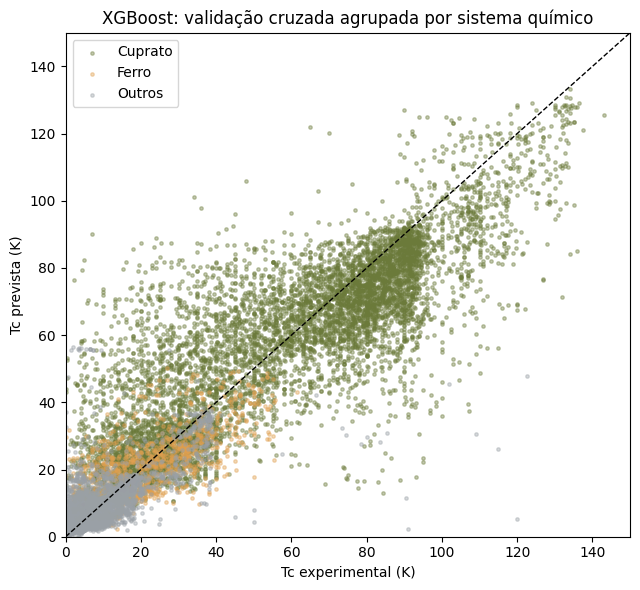

In [ ]:
COLS_HAMIDIEH = [c for c in train.columns if c != 'critical_temp']
COLS_XGB = COLS_HAMIDIEH + ['eletroneg_pond', 'tem_terra_rara']
X_todas = dados[COLS_XGB]
y = dados['critical_temp'].to_numpy()

X_lin10 = montar_X(dados, cols).drop(columns='const')
X_lin_todas = X_todas.assign(**{'Família: Ferro': (dados.familia == 'Ferro').astype(int),
                                'Família: Outros': (dados.familia == 'Outros').astype(int)})

def novo_xgb():
    return XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=8, subsample=0.8,
                        random_state=SEED, n_jobs=-1)

MODELOS = {'Regressão linear (10 variáveis)': (LinearRegression, X_lin10),
           'Regressão linear (todas as variáveis)': (LinearRegression, X_lin_todas),
           'XGBoost': (novo_xgb, X_todas)}
VALIDACOES = {'Aleatória (KFold)': list(KFold(5, shuffle=True, random_state=SEED).split(X_todas)),
              'Agrupada por sistema (GroupKFold)': list(GroupKFold(5).split(X_todas, groups=grupos_sistema))}

def avaliar(fabrica, X, particoes):
    """Treina em cada partição; devolve métricas por partição e as previsões fora da partição."""
    X = np.asarray(X, dtype=float)
    oof = np.empty(len(y))
    metricas = []
    for treino, teste in particoes:
        modelo = fabrica().fit(X[treino], y[treino])
        oof[teste] = modelo.predict(X[teste])
        metricas.append((r2_score(y[teste], oof[teste]), mean_absolute_error(y[teste], oof[teste]),
                         np.sqrt(mean_squared_error(y[teste], oof[teste]))))
    return np.array(metricas), oof

linhas, previsoes_oof = [], {}
for nome_cv, particoes in VALIDACOES.items():
    for nome_modelo, (fabrica, X) in MODELOS.items():
        m, oof = avaliar(fabrica, X, particoes)
        previsoes_oof[(nome_cv, nome_modelo)] = oof
        linhas.append({'Validação': nome_cv, 'Modelo': nome_modelo,
                       'R²': f'{m[:, 0].mean():.3f} ± {m[:, 0].std(ddof=1):.3f}',
                       'MAE (K)': f'{m[:, 1].mean():.1f}', 'RMSE (K)': f'{m[:, 2].mean():.1f}'})
tab_modelos = pd.DataFrame(linhas)
print(tab_modelos.to_string(index=False))

# Desempenho por família na validação agrupada (XGBoost)
dados['Tc_prevista_agrupada'] = previsoes_oof[('Agrupada por sistema (GroupKFold)', 'XGBoost')]
por_familia = []
for fam in FAMILIAS:
    s = dados.familia == fam
    por_familia.append({'Família': fam, 'n': int(s.sum()),
                        'MAE (K)': mean_absolute_error(dados.critical_temp[s], dados.Tc_prevista_agrupada[s]),
                        'R²': r2_score(dados.critical_temp[s], dados.Tc_prevista_agrupada[s])})
tab_familia = pd.DataFrame(por_familia)
print('\nXGBoost, validação agrupada, por família:')
print(tab_familia.round(3).to_string(index=False))
MAE_FAMILIA = tab_familia.set_index('Família')['MAE (K)']

# Figura: previsto x experimental (validação agrupada)
fig, ax = plt.subplots(figsize=(6.5, 6))
for fam, cor in zip(FAMILIAS, ['#6b7a3a', '#e0a050', '#9aa0a6']):
    s = dados.familia == fam
    ax.scatter(dados.critical_temp[s], dados.Tc_prevista_agrupada[s], s=6, alpha=0.4, color=cor, label=fam)
lim = [0, 150]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Tc experimental (K)'); ax.set_ylabel('Tc prevista (K)')
ax.set_title('XGBoost: validação cruzada agrupada por sistema químico')
ax.legend()
plt.tight_layout()
plt.savefig('reports/fig3_previsto_vs_experimental.png', dpi=300, bbox_inches='tight')
plt.show()

### SHAP: em que variáveis o modelo se apoia?

Usado apenas como verificação de coerência com a análise estatística. Em variáveis correlacionadas,
a importância pode se concentrar de forma quase arbitrária em uma delas.

Dez variáveis mais importantes (|SHAP| médio, em K):
range_ThermalConductivity        18.530001
wtd_gmean_ThermalConductivity     3.590000
range_atomic_radius               2.070000
wtd_gmean_Valence                 2.010000
wtd_std_ElectronAffinity          1.730000
mean_Density                      1.450000
tem_terra_rara                    1.250000
std_Density                       1.100000
wtd_mean_Valence                  0.960000
gmean_ElectronAffinity            0.880000
Razão entre a 1ª e a 2ª: 5.2
Posição do indicador de terras-raras: 7º (|SHAP| médio = 1.25 K)


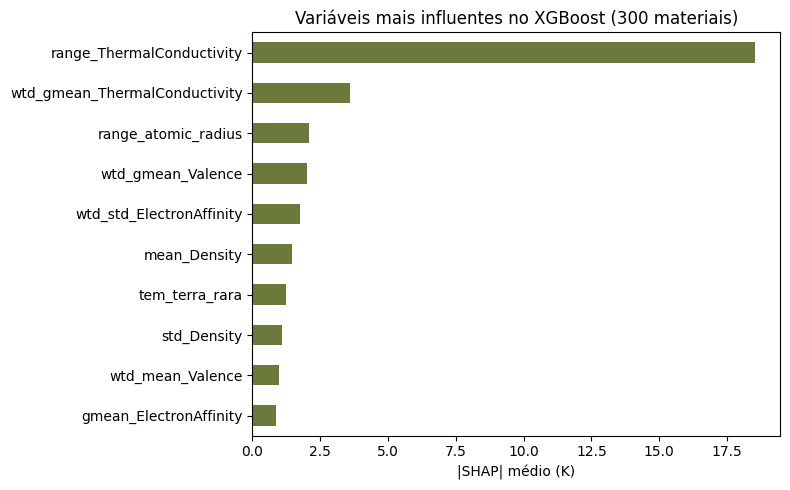

In [ ]:
modelo_final = novo_xgb().fit(X_todas, y)   # treinado com toda a base; usado no SHAP e nos compostos inéditos
amostra_shap = X_todas.sample(300, random_state=SEED)
valores_shap = shap.TreeExplainer(modelo_final).shap_values(amostra_shap)
importancia = pd.Series(np.abs(valores_shap).mean(axis=0), index=COLS_XGB).sort_values(ascending=False)
print('Dez variáveis mais importantes (|SHAP| médio, em K):')
print(importancia.head(10).round(2).to_string())
print(f'Razão entre a 1ª e a 2ª: {importancia.iloc[0] / importancia.iloc[1]:.1f}')
print(f'Posição do indicador de terras-raras: {importancia.index.get_loc("tem_terra_rara") + 1}º '
      f'(|SHAP| médio = {importancia["tem_terra_rara"]:.2f} K)')

fig, ax = plt.subplots(figsize=(8, 5))
importancia.head(10)[::-1].plot.barh(ax=ax, color='#6b7a3a')
ax.set_xlabel('|SHAP| médio (K)')
ax.set_title('Variáveis mais influentes no XGBoost (300 materiais)')
plt.tight_layout()
plt.savefig('reports/fig4_shap.png', dpi=300, bbox_inches='tight')
plt.show()

## Etapa 6 — Therm° Sustainability Score (TSS)

Índice de 0 a 1 (1 = mais sustentável), organizado em três pilares:

| Pilar | Indicador | Fonte |
|---|---|---|
| Ambiental | Escassez geológica (abundância crustal, escala log) | CRC Handbook |
| Ambiental | Pegada de carbono da produção (mineração, purificação e refino) | Nuss e Eckelman (2014), Tabela S38 |
| Social | Perigo à saúde humana (pontuação contínua) | ATSDR Substance Priority List 2025 |
| Econômico | Risco de suprimento (elemento mais crítico do material) | Comissão Europeia (2023) |

O TSS é a média dos três pilares. A célula também reimplementa a extração das 81 variáveis de Hamidieh
(necessária para os compostos inéditos da Etapa 8) e confere o resultado contra o `train.csv`.

In [ ]:
# --- Propriedades elementares e extração das 81 variáveis de Hamidieh (2018)
# Tabela de propriedades do repositório original do autor (github.com/khamidieh/predict_tc).
ELEMENT_DATA = pd.read_csv(StringIO("""Element,AtomicMass,FirstIonizationEnergy,AtomicRadius,Density,ElectronAffinity,FusionHeat,ThermalConductivity,Valence
H,1.00794,1311.3,53,0.0899,74.3,0.558,0.1805,1
He,4.002602,2361.3,31,0.1785,1.5,0.02,0.1513,0
Li,6.941,519.9,167,535.0,61.1,3.0,85.0,1
Be,9.012182,898.8,112,1848.0,1.5,7.95,190.0,2
B,10.811,800.2,87,2460.0,28.2,50.0,27.0,3
C,12.0107,1085.7,67,2260.0,155.4,105.0,140.0,4
N,14.0067,1401.5,56,1.251,8.5,0.36,0.02583,3
O,15.9994,1313.1,48,1.429,142.5,0.222,0.02658,2
F,18.9984032,1680.0,42,1.696,329.5,0.26,0.0277,1
Ne,20.1791,2079.4,38,0.9,1.5,0.34,0.0491,0
Na,22.98976928,495.6,190,968.0,54.3,2.6,140.0,1
Mg,24.305,737.3,145,1738.0,1.5,8.7,160.0,2
Al,26.9815386,577.2,118,2700.0,44.0,10.7,235.0,3
Si,28.0855,786.0,111,2330.0,135.1,50.2,150.0,4
P,30.973762,1011.2,98,1823.0,72.5,0.64,0.236,5
S,32.065,999.0,87,1960.0,201.5,1.73,0.205,6
Cl,35.453,1254.9,79,3.214,350.5,3.2,0.0089,5
Ar,39.948,1519.6,71,1.784,1.5,1.18,0.01772,0
K,39.0983,418.5,243,856.0,49.9,2.33,100.0,1
Ca,40.078,589.4,194,1550.0,3.87,8.54,200.0,2
Sc,44.955912,630.8,184,2985.0,19.6,16.0,16.0,3
Ti,47.867,657.8,176,4507.0,9.1,18.7,22.0,4
V,50.9415,650.1,171,6110.0,52.1,22.8,31.0,5
Cr,51.9961,652.4,166,7190.0,65.8,20.5,94.0,6
Mn,54.938045,716.8,161,7470.0,1.5,13.2,7.7,4
Fe,55.845,759.1,156,7874.0,17.2,13.8,79.0,3
Co,58.933195,758.1,152,8900.0,65.2,16.2,100.0,4
Ni,58.6934,736.2,149,8908.0,113.5,17.2,91.0,2
Cu,63.546,745.0,145,8960.0,119.9,13.1,400.0,2
Zn,65.38,905.8,142,7140.0,1.5,7.35,120.0,2
Ga,69.723,578.7,136,5904.0,30.4,5.59,29.0,3
Ge,72.63,760.0,125,5323.0,120.5,31.8,60.0,4
As,74.9216,946.2,114,5727.0,79.5,27.7,50.0,5
Se,78.96,940.4,103,4819.0,196.5,5.4,0.52,6
Br,79.904,1142.0,94,3120.0,326.1,5.8,0.12,5
Kr,83.798,1350.0,87,3.75,1.5,1.64,0.00943,2
Rb,85.4678,402.8,265,1532.0,48.4,2.19,58.0,1
Sr,87.62,549.0,219,2630.0,6.53,8.0,35.0,2
Y,88.90585,615.4,212,4472.0,31.1,11.4,17.0,3
Zr,91.224,659.7,206,6511.0,42.6,21.0,23.0,4
Nb,92.90638,663.6,198,8570.0,87.6,26.8,54.0,5
Mo,95.96,684.8,190,10280.0,73.4,36.0,139.0,6
Tc,98.0,702.2,183,11500.0,54.5,23.0,51.0,6
Ru,101.07,710.3,178,12370.0,102.8,25.7,120.0,6
Rh,102.9055,719.5,173,12450.0,111.2,21.7,150.0,6
Pd,106.42,803.5,169,12023.0,55.2,16.7,71.0,4
Ag,107.8682,730.5,165,10490.0,127.1,11.3,430.0,1
Cd,112.411,867.2,161,8650.0,1.5,6.3,96.0,2
In,114.818,558.0,156,7310.0,30.4,3.26,82.0,3
Sn,118.71,708.2,145,7310.0,108.8,7.0,67.0,4
Sb,121.76,833.3,133,6697.0,104.7,19.7,24.0,5
Te,127.6,869.0,123,6240.0,191.7,17.5,3.0,6
I,126.90447,1008.3,115,4940.0,296.7,7.76,0.449,7
Xe,131.293,1170.0,108,5.9,1.5,2.3,0.00565,6
Cs,132.9054519,375.5,298,1879.0,47.0,2.09,36.0,1
Ba,137.327,502.5,253,3510.0,15.45,8.0,18.0,2
La,138.90547,541.1,195,6146.0,49.5,6.3,13.0,3
Ce,140.116,540.1,185,6689.0,51.5,5.5,11.0,4
Pr,140.90765,526.6,247,6640.0,51.5,6.9,13.0,4
Nd,144.242,531.5,206,7010.0,51.5,7.1,17.0,3
Pm,145.0,536.0,205,7264.0,51.5,7.7,15.0,3
Sm,150.36,540.1,238,7353.0,51.5,8.5,13.0,3
Eu,151.964,546.9,231,5244.0,51.5,9.3,14.0,3
Gd,157.25,594.2,233,7901.0,51.5,10.0,11.0,3
Tb,158.92535,569.0,225,8219.0,51.5,10.8,11.0,3
Dy,162.5,567.0,228,8551.0,51.5,11.1,11.0,3
Ho,164.93032,574.0,226,8795.0,51.5,17.0,16.0,3
Er,167.259,581.0,226,9066.0,51.5,19.9,15.0,3
Tm,168.93421,589.0,222,9320.0,51.5,16.8,17.0,3
Yb,173.054,603.0,222,6570.0,51.5,7.7,39.0,3
Lu,174.9668,513.0,217,9841.0,51.5,22.0,16.0,3
Hf,178.49,575.2,208,13310.0,1.5,25.5,23.0,4
Ta,180.94788,760.1,200,16650.0,32.5,36.0,57.0,5
W,183.84,769.7,193,19250.0,80.1,35.0,170.0,6
Re,186.207,759.1,188,21020.0,16.0,33.0,48.0,7
Os,190.23,819.8,185,22590.0,107.6,31.0,87.0,6
Ir,192.217,868.1,180,22560.0,152.5,26.0,150.0,6
Pt,195.084,868.1,177,21450.0,206.8,20.0,71.0,6
Au,196.966569,889.3,174,19300.0,224.3,12.5,320.0,5
Hg,200.59,1006.0,171,13534.0,1.5,2.29,8.3,2
Tl,204.3833,588.9,156,11850.0,20.7,4.2,46.0,3
Pb,207.2,715.2,154,11340.0,36.6,4.77,35.0,4
Bi,208.9804,702.9,143,9780.0,92.7,10.9,8.0,5
Po,209.0,813.1,135,9196.0,184.8,13.0,,6
At,210.0,916.3,127,,271.6,6.0,2.0,7
Rn,222.0,1036.5,120,9.73,1.5,3.0,0.00361,6"""))
ELEMENT_DATA = ELEMENT_DATA.set_index('Element')

PROPRIEDADES = [('AtomicMass', 'atomic_mass'), ('FirstIonizationEnergy', 'fie'),
                ('AtomicRadius', 'atomic_radius'), ('Density', 'Density'),
                ('ElectronAffinity', 'ElectronAffinity'), ('FusionHeat', 'FusionHeat'),
                ('ThermalConductivity', 'ThermalConductivity'), ('Valence', 'Valence')]
ESTATISTICAS = ['mean', 'wtd_mean', 'gmean', 'wtd_gmean', 'entropy', 'wtd_entropy',
                'range', 'wtd_range', 'std', 'wtd_std']

def _estatisticas(v, p):
    """Dez estatísticas de uma propriedade v, com proporções p (ignora valores ausentes)."""
    ok = ~np.isnan(v)
    v, p = v[ok], p[ok]
    with np.errstate(divide='ignore', invalid='ignore'):
        media      = v.mean()
        media_p    = np.sum(p * v)
        gmedia     = np.exp(np.mean(np.log(np.abs(v))))
        gmedia_p   = np.exp(np.sum(p * np.log(np.abs(v))))
        t          = np.abs(v) / np.sum(np.abs(v))
        entropia   = -np.sum(t * np.log(t))
        t          = p * np.abs(v) / np.sum(p * np.abs(v))
        entropia_p = -np.sum(t * np.log(t))
        amplitude   = v.max() - v.min()
        amplitude_p = np.max(p * v) - np.min(p * v)
        desvio      = np.sqrt(np.mean((v - media) ** 2))
        desvio_p    = np.sqrt(np.sum((v - media_p) ** 2 * p))
    return [media, media_p, gmedia, gmedia_p, entropia, entropia_p,
            amplitude, amplitude_p, desvio, desvio_p]

def variaveis_hamidieh(composicao):
    """composicao: dict {elemento: coeficiente estequiométrico}. Retorna as 81 variáveis."""
    composicao = {e: float(v) for e, v in composicao.items() if v > 0}
    elementos = list(composicao)
    x = np.array([composicao[e] for e in elementos])
    p = x / x.sum()
    tabela = ELEMENT_DATA.loc[elementos]
    saida = [float(len(elementos))]
    for coluna, _ in PROPRIEDADES:
        saida += _estatisticas(tabela[coluna].to_numpy(float), p)
    return pd.Series(saida, index=COLS_HAMIDIEH)


# Validação: recalcula 1.000 compostos sorteados e compara com as variáveis da base
amostra = dados.sample(1000, random_state=SEED).index
recalculado = pd.DataFrame([variaveis_hamidieh(comp_dados.loc[i].to_dict()) for i in amostra], index=amostra)
original = dados.loc[amostra, COLS_HAMIDIEH]
iguais = np.isclose(recalculado.to_numpy(), original.to_numpy(), rtol=1e-6, atol=1e-6)
assert iguais.all(), 'A extração não reproduz o train.csv.'
print(f'Extração validada: 1.000 compostos x 81 variáveis iguais à base '
      f'(maior diferença: {(recalculado - original).abs().to_numpy().max():.1e}).')

def _vetor(tabela):
    return np.array([tabela.get(e, 0.0) for e in elem_cols], dtype=float)

def eletroneg_pond(matriz_comp):
    """Mesma definição da Etapa 1: média ponderada sobre elementos com valor conhecido."""
    C = np.asarray(matriz_comp, dtype=float)[:, mask_en]
    return (C @ en.values[mask_en]) / C.sum(axis=1)

# --- Abundância crustal (ppm). Valores da tabela "Abundance of elements in the Earth's crust"
# do CRC Handbook of Chemistry and Physics (conferir o valor do S antes de citar).
ABUNDANCIA = {
    'H':1400,'He':0.008,'Li':20,'Be':2.8,'B':10,'C':200,'N':19,'O':461000,
    'F':585,'Ne':0,'Na':23600,'Mg':23300,'Al':82300,'Si':282000,'P':1050,
    'S':260,'Cl':145,'Ar':0,'K':20900,'Ca':41500,'Sc':22,'Ti':5650,
    'V':120,'Cr':102,'Mn':950,'Fe':56300,'Co':25,'Ni':84,'Cu':60,
    'Zn':70,'Ga':19,'Ge':1.5,'As':1.8,'Se':0.05,'Br':2.4,'Kr':0,
    'Rb':90,'Sr':370,'Y':33,'Zr':165,'Nb':20,'Mo':1.2,'Tc':0,
    'Ru':0.001,'Rh':0.0004,'Pd':0.015,'Ag':0.075,'Cd':0.15,
    'In':0.25,'Sn':2.3,'Sb':0.2,'Te':0.001,'I':0.45,'Xe':0,
    'Cs':3,'Ba':425,'La':39,'Ce':66,'Pr':9.1,'Nd':41,'Pm':0,
    'Sm':7.1,'Eu':2,'Gd':6.2,'Tb':1.2,'Dy':5.2,'Ho':1.3,
    'Er':3.5,'Tm':0.52,'Yb':3.2,'Lu':0.8,'Hf':3,'Ta':2,
    'W':1.3,'Re':0.0007,'Os':0.002,'Ir':0.0004,'Pt':0.004,
    'Au':0.0011,'Hg':0.067,'Tl':0.53,'Pb':14,'Bi':0.025,
    'Po':0,'At':0,'Rn':0,
}
ABUND_MIN, LOG_MIN, LOG_MAX = 0.001, -3.0, 5.7

# =============================================================================
# Therm° Sustainability Score (TSS) — três pilares
#   Ambiental : escassez geológica, pegada de carbono da produção
#   Social    : perigo do material à saúde humana
#   Econômico : risco de suprimento
# =============================================================================

# --- Perigo intrínseco: pontuação contínua da ATSDR Substance Priority List 2025
# (pontos totais; a lista é uma priorização por toxicidade, frequência e exposição).
# Escala: 0 = último lugar da lista (767 pontos) ou ausente; 1 = primeiro lugar (1796).
ATSDR_PONTOS_2025 = {
    'Pb': 1796, 'As': 1642, 'Cd': 1561, 'Ni': 1495, 'Be': 1474, 'Mn': 1458, 'Hg': 1399,
    'Sb': 1374, 'Tl': 1356, 'V': 1351, 'Cr': 1341, 'Cu': 1307, 'Co': 1294, 'Th': 1277,
    'Zn': 1263, 'Ba': 1232, 'Se': 1220, 'Ag': 1214, 'Fe': 1197, 'Al': 1153, 'Mo': 987,
    'F': 915, 'B': 857, 'Sn': 803, 'Sr': 775,
}
PONTOS_MIN, PONTOS_MAX = 767, 1796
PERIGO = {e: (ATSDR_PONTOS_2025[e] - PONTOS_MIN) / (PONTOS_MAX - PONTOS_MIN)
          if e in ATSDR_PONTOS_2025 else 0.0 for e in elem_cols}
# Exclusão na triagem: elementos no terço superior da lista (mesmo critério de antes)
ELEMENTOS_ALTA_TOX = ['Pb', 'As', 'Cd', 'Ni', 'Be', 'Mn', 'Hg', 'Sb', 'Tl']

# --- Risco de suprimento: Supply Risk (SR), Comissão Europeia (2023), etapa-gargalo.
RISCO_SUPRIMENTO = {
    'H': 0.5, 'He': 1.2, 'Li': 1.9, 'Be': 1.8, 'B': 3.6, 'F': 1.1, 'Ne': 0.7,
    'Mg': 0.6, 'Al': 1.2, 'Si': 0.3, 'P': 3.3, 'S': 0.3, 'K': 0.7, 'Ca': 0.3,
    'Sc': 2.4, 'Ti': 0.5, 'V': 2.3, 'Cr': 0.7, 'Mn': 1.2, 'Fe': 0.5, 'Co': 2.8,
    'Ni': 0.5, 'Cu': 0.1, 'Zn': 0.2, 'Ga': 3.9, 'Ge': 1.8, 'As': 1.9, 'Se': 0.3,
    'Kr': 0.7, 'Sr': 2.6, 'Y': 3.5, 'Zr': 0.8, 'Nb': 4.4, 'Mo': 0.8, 'Ru': 3.8,
    'Rh': 2.4, 'Pd': 1.5, 'Ag': 0.8, 'Cd': 0.2, 'In': 0.6, 'Sn': 0.9, 'Sb': 1.8,
    'Te': 0.3, 'Xe': 0.8, 'Ba': 1.3, 'La': 3.5, 'Ce': 4.0, 'Pr': 3.2, 'Nd': 4.5,
    'Sm': 3.5, 'Eu': 5.6, 'Gd': 3.3, 'Tb': 4.9, 'Dy': 5.6, 'Ho': 5.6, 'Er': 5.6,
    'Tm': 5.6, 'Yb': 5.6, 'Lu': 5.6, 'Hf': 1.5, 'Ta': 1.3, 'W': 1.2, 'Re': 0.5,
    'Ir': 3.9, 'Pt': 2.1, 'Au': 0.4, 'Pb': 0.1, 'Bi': 1.9,
}
SR_MAX = 5.6

# --- Pegada de carbono da produção (berço ao portão: mineração, purificação e refino),
# em kg CO2-eq por kg de elemento: Nuss & Eckelman (2014), Tabela S38 (linhas TOTAL,
# média ponderada pela produção mundial de 2008). Inclui o intervalo de 95% (p2,5–p97,5).
# A demanda de energia (CED) da mesma tabela não entra: correlação de Spearman 0,99 com o GWP.
LCA = pd.read_csv('lca_nuss_eckelman_2014.csv').set_index('elemento')
# Elementos sem dado (O, C, N, F, S, Si etc.) entram com impacto zero;
# a fração em massa coberta pelos dados é reportada para cada material.
V_GWP, V_GWP_LO, V_GWP_HI = (_vetor(LCA[c].to_dict()) for c in ['gwp_kgCO2eq_kg', 'gwp_p2_5', 'gwp_p97_5'])
V_TEM_LCA = _vetor({e: 1.0 for e in LCA.index})
GWP_LOG_MIN, GWP_LOG_MAX = np.log10(LCA['gwp_kgCO2eq_kg'].min()), np.log10(LCA['gwp_kgCO2eq_kg'].max())

V_LOG_ABUND = np.log10(np.maximum(_vetor(ABUNDANCIA), ABUND_MIN))
V_PERIGO = _vetor(PERIGO)
V_SR = _vetor(RISCO_SUPRIMENTO)
V_MASSA = ELEMENT_DATA['AtomicMass'].reindex(elem_cols).to_numpy(float)

def _escala_carbono(gwp_material):
    """GWP por kg de material em escala log: 0 = elemento de menor GWP (Ba), 1 = maior (Rh)."""
    lg = np.log10(np.maximum(gwp_material, 10 ** GWP_LOG_MIN))
    return np.clip((lg - GWP_LOG_MIN) / (GWP_LOG_MAX - GWP_LOG_MIN), 0, 1)

INDICADORES = ['escassez', 'carbono', 'perigo', 'suprimento']
PILARES = {'Ambiental': ['escassez', 'carbono'],
           'Social':    ['perigo'],
           'Econômico': ['suprimento']}

def indicadores_tss(matriz_comp, v_gwp=None):
    """Quatro indicadores em escala 0–1 (1 = mais sustentável) para cada material.
    v_gwp (opcional): vetor alternativo de GWP por elemento (análise de incerteza)."""
    C = np.asarray(matriz_comp, dtype=float)
    x_mol = C / C.sum(axis=1)[:, None]
    massa = C * V_MASSA
    x_massa = massa / massa.sum(axis=1)[:, None]
    gwp = V_GWP if v_gwp is None else v_gwp
    ind = pd.DataFrame({
        'escassez':   np.clip((x_mol @ V_LOG_ABUND - LOG_MIN) / (LOG_MAX - LOG_MIN), 0, 1),
        'carbono':    1 - _escala_carbono(x_massa @ gwp),
        'perigo':     1 - x_mol @ V_PERIGO,
        'suprimento': 1 - np.clip(np.where(C > 0, V_SR[None, :], 0).max(axis=1) / SR_MAX, 0, 1),
    })
    ind['gwp_kgCO2eq_por_kg'] = x_massa @ gwp      # valor físico, para reportar
    ind['cobertura_lca'] = x_massa @ V_TEM_LCA      # fração em massa com dado de GWP
    return ind

def tss(matriz_comp):
    """TSS = média dos três pilares; cada pilar = média dos seus indicadores."""
    ind = indicadores_tss(matriz_comp)
    pilares = pd.DataFrame({p: ind[cols].mean(axis=1) for p, cols in PILARES.items()})
    return pilares.mean(axis=1).to_numpy(), pilares, ind

# YBCO como referência
ybco = np.zeros((1, len(elem_cols)))
for el, q in {'Y': 1, 'Ba': 2, 'Cu': 3, 'O': 7}.items():
    ybco[0, elem_cols.index(el)] = q
tss_ybco, pilares_ybco, ind_ybco = tss(ybco)
print(f'\nTSS do YBCO (referência): {tss_ybco[0]:.2f}')
print(pd.concat([pilares_ybco, ind_ybco[INDICADORES]], axis=1).round(2).to_string(index=False))

Extração validada: 1.000 compostos x 81 variáveis iguais à base (maior diferença: 6.9e-11).

TSS do YBCO (referência): 0.66
 Ambiental  Social  Econômico  escassez  carbono  perigo  suprimento
      0.79    0.81       0.38       0.8     0.78    0.81        0.38


## Etapa 7 — Triagem dos materiais da base

Critérios: sem terras-raras; sem elementos de alta toxicidade (Pb, As, Cd, Ni, Be, Mn, Hg, Sb, Tl — terço superior
da lista da ATSDR); sem hidretos binários; sem fórmulas de oxigênio incompleto; Tc experimental ≥ 40 K.

Os materiais são ordenados pelo escore **S = 0,6·Tc,norm + 0,4·TSS**, em que Tc,norm é a Tc **experimental**
normalizada. O XGBoost não substitui a Tc medida: ele é usado como **verificação**. Considera-se que o modelo
reproduz a Tc registrada quando o erro da previsão da validação agrupada fica abaixo de 2 × MAE da família.

Candidatos: 327  ->  Cuprato: 313, Outros: 7, Ferro: 7
Limites de verificação (2 × MAE da família): Cuprato: 26.0 K, Ferro: 13.9 K, Outros: 6.1 K
Tc reproduzida pelo modelo: 232 (71%)
Entre os 30 de maior S: 13 reproduzidos

Dez de maior S, com Tc reproduzida pelo modelo (Tabela de candidatos):
                material familia  critical_temp  Tc_prevista_agrupada   TSS     S  Tc reproduzida
      Cu4.6C0.4Ba2Ca3O12 Cuprato          117.0               100.999 0.823 0.831            True
   C0.3Ba2Ca4Cu5.7O11.18 Cuprato          117.5                99.691 0.813 0.831            True
      C0.5Ba2Ca3Cu4.5O11 Cuprato          117.0               100.236 0.820 0.830            True
 Cu0.68C0.32Ba2Ca3Cu4O11 Cuprato          117.0                98.379 0.818 0.830            True
   C0.3Ba2Ca4Cu5.7O10.77 Cuprato          116.7                99.376 0.811 0.825            True
         Ba2Ca3Cu4O10.35 Cuprato          116.0                90.493 0.822 0.825            True
   C0.3Ba2Ca4Cu5.7

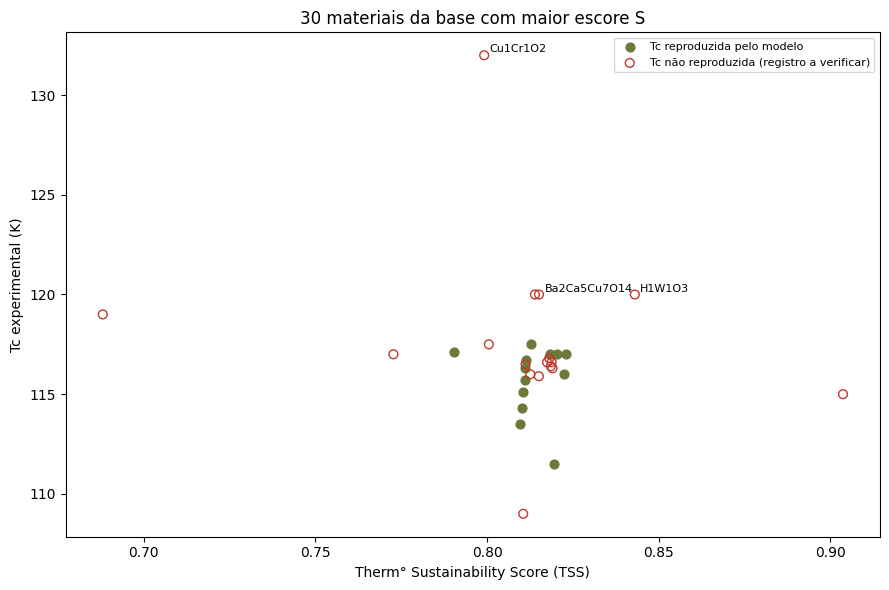

In [ ]:
tss_base, pilares_base, ind_base = tss(comp_dados.to_numpy())
dados['TSS'] = tss_base
for pilar in pilares_base:
    dados[f'TSS_{pilar}'] = pilares_base[pilar].values
dados['GWP (kg CO2-eq/kg)'] = ind_base['gwp_kgCO2eq_por_kg'].values

alta_tox = (comp_dados[ELEMENTOS_ALTA_TOX] > 0).any(axis=1).values
filtro = ((dados.tem_terra_rara == 0) & ~alta_tox & ~dados.hidreto_binario
          & ~dados.oxigenio_incompleto & (dados.critical_temp >= 40))
candidatos = dados[filtro].copy()

tc_min, tc_max = candidatos['critical_temp'].min(), candidatos['critical_temp'].max()
def escore_combinado(tc, valor_tss):
    return 0.6 * np.clip((tc - tc_min) / (tc_max - tc_min), 0, 1) + 0.4 * valor_tss

candidatos['S'] = escore_combinado(candidatos['critical_temp'], candidatos['TSS'])
candidatos['erro (K)'] = (candidatos['Tc_prevista_agrupada'] - candidatos['critical_temp']).abs()
candidatos['limite (K)'] = 2 * candidatos['familia'].map(MAE_FAMILIA)
candidatos['Tc reproduzida'] = candidatos['erro (K)'] <= candidatos['limite (K)']
candidatos = candidatos.sort_values('S', ascending=False)

print(f'Candidatos: {len(candidatos)}  ->  ' +
      ', '.join(f'{f}: {n}' for f, n in candidatos.familia.value_counts().items()))
print('Limites de verificação (2 × MAE da família): ' +
      ', '.join(f'{f}: {v:.1f} K' for f, v in (2 * MAE_FAMILIA).items()))
print(f'Tc reproduzida pelo modelo: {int(candidatos["Tc reproduzida"].sum())} '
      f'({candidatos["Tc reproduzida"].mean() * 100:.0f}%)')
print(f'Entre os 30 de maior S: {int(candidatos.head(30)["Tc reproduzida"].sum())} reproduzidos')

colunas = ['material', 'familia', 'critical_temp', 'Tc_prevista_agrupada', 'TSS', 'S', 'Tc reproduzida']
print('\nDez de maior S, com Tc reproduzida pelo modelo (Tabela de candidatos):')
print(candidatos[candidatos['Tc reproduzida']][colunas].head(10).round(3).to_string(index=False))
print('\nDez de maior S que o modelo NÃO reproduziu (registros a verificar):')
print(candidatos[~candidatos['Tc reproduzida']][colunas].head(10).round(3).to_string(index=False))

for nome in ['Cu1Cr1O2', 'H2S1', 'H1W1O3']:
    linha = dados[dados.material == nome]
    if len(linha):
        r = linha.iloc[0]
        print(f'\n{nome}: Tc exp = {r.critical_temp:.1f} K; Tc prevista (agrupada) = '
              f'{r.Tc_prevista_agrupada:.1f} K; TSS = {r.TSS:.2f}; na triagem: {nome in set(candidatos.material)}')

candidatos[colunas + ['TSS_Ambiental', 'TSS_Social', 'TSS_Econômico', 'GWP (kg CO2-eq/kg)']] \
    .round(4).to_csv('reports/candidatos_base.csv', index=False)

# Figura: Tc experimental x TSS dos 30 de maior S
top30 = candidatos.head(30)
fig, ax = plt.subplots(figsize=(9, 6))
ok = top30['Tc reproduzida']
ax.scatter(top30.TSS[ok], top30.critical_temp[ok], color='#6b7a3a', s=40, label='Tc reproduzida pelo modelo')
ax.scatter(top30.TSS[~ok], top30.critical_temp[~ok], facecolors='none', edgecolors='#c0392b', s=40,
           label='Tc não reproduzida (registro a verificar)')
for _, r in top30[~ok].nlargest(3, 'critical_temp').iterrows():
    ax.annotate(r.material, (r.TSS, r.critical_temp), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('Therm° Sustainability Score (TSS)'); ax.set_ylabel('Tc experimental (K)')
ax.set_title('30 materiais da base com maior escore S')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('reports/fig5_triagem.png', dpi=300, bbox_inches='tight')
plt.show()

## Etapa 8 — Compostos inéditos por substituição química

Substituições aplicadas aos 20 materiais de maior S com Tc reproduzida. Ficam de fora as trocas que retiram
todo o cobre ou todo o oxigênio de um cuprato (ele deixaria de ser cuprato) e as que introduzem terras-raras
ou elementos de alta toxicidade. As 81 variáveis são recalculadas a partir da nova fórmula, e a Tc é estimada pelo
XGBoost treinado com toda a base.

In [ ]:
SUBSTITUICOES = {'Ba': ['Sr', 'Ca'], 'Bi': ['Sb'], 'Nb': ['Ta', 'V'], 'Zr': ['Hf', 'Ti'],
                 'In': ['Ga'], 'Sn': ['Ge', 'Si'], 'Ag': ['Au']}
TOKEN = re.compile(r'([A-Z][a-z]?)([0-9]*\.?[0-9]*)')

def formula(origem, composicao, el_orig, sub):
    ordem = []
    for el, _ in TOKEN.findall(origem):
        el = sub if el == el_orig else el
        if composicao.get(el, 0) > 0 and el not in ordem:
            ordem.append(el)
    ordem += [el for el, v in composicao.items() if v > 0 and el not in ordem]
    return ''.join(f'{el}{composicao[el]:g}' for el in ordem)

def chave(composicao):
    total = sum(composicao.values())
    return tuple(sorted((el, round(v / total, 4)) for el, v in composicao.items() if v > 0))

chaves_base = {chave(comp_dados.loc[i][comp_dados.loc[i] > 0].to_dict()) for i in dados.index}
sistemas_base = set(dados['sistema'])

origens = candidatos[candidatos['Tc reproduzida']].head(20)
gerados = {}
for i, r in origens.iterrows():
    comp_origem = comp_dados.loc[i][comp_dados.loc[i] > 0].to_dict()
    for el_orig, substitutos in SUBSTITUICOES.items():
        if el_orig not in comp_origem:
            continue
        for sub in substitutos:
            nova = dict(comp_origem)
            nova[sub] = nova.get(sub, 0) + nova.pop(el_orig)
            if any(e in TERRAS_RARAS or e in ELEMENTOS_ALTA_TOX for e in nova):
                continue
            k = chave(nova)
            if k in gerados or k in chaves_base:
                continue
            gerados[k] = {'composto': formula(r.material, nova, el_orig, sub), 'origem': r.material,
                          'substituição': f'{el_orig} → {sub}', 'composicao': nova,
                          'sistema na base': '-'.join(sorted(nova)) in sistemas_base}

lista = list(gerados.values())
matriz = np.zeros((len(lista), len(elem_cols)))
for j, g in enumerate(lista):
    for el, q in g['composicao'].items():
        matriz[j, elem_cols.index(el)] = q
X_novos = pd.DataFrame([variaveis_hamidieh(g['composicao']) for g in lista])
X_novos['eletroneg_pond'] = eletroneg_pond(matriz)
X_novos['tem_terra_rara'] = 0
tss_novos, _, _ = tss(matriz)

ineditos = pd.DataFrame({'composto': [g['composto'] for g in lista],
                         'origem': [g['origem'] for g in lista],
                         'substituição': [g['substituição'] for g in lista],
                         'Tc prevista (K)': modelo_final.predict(X_novos[COLS_XGB]),
                         'TSS': tss_novos,
                         'sistema na base': [g['sistema na base'] for g in lista]})
print(f'Compostos inéditos gerados: {len(ineditos)} '
      f'({int((~ineditos["sistema na base"]).sum())} em sistemas químicos ausentes da base)')
print(f'Mediana da Tc dos materiais de origem: {origens.critical_temp.median():.1f} K')
print('\nTc prevista mediana por tipo de substituição:')
print(ineditos.groupby('substituição')['Tc prevista (K)'].agg(['count', 'median']).round(1)
      .sort_values('median', ascending=False).to_string())

ineditos['sistema'] = [ '-'.join(sorted(g['composicao'])) for g in lista]
melhores = (ineditos.sort_values('Tc prevista (K)', ascending=False)
            .drop_duplicates('sistema').head(10).drop(columns='sistema'))
print('\nMaior Tc prevista, um composto por sistema químico:')
print(melhores.round(3).to_string(index=False))
ineditos.drop(columns='sistema').round(4).to_csv('reports/candidatos_ineditos.csv', index=False)

## Etapa 9 — Robustez do ranking e perfil de sustentabilidade

Os pesos do TSS e do escore S são escolhas. Para testar se o ranking depende delas, sorteamos 5.000 cenários
(pesos dos indicadores, peso da Tc entre 0,4 e 0,8 e pegada de carbono de cada elemento dentro do seu
intervalo de 95%) e contamos quantas vezes cada candidato fica em 1º lugar e entre os cinco primeiros.

In [ ]:
# =============================================================================
# Análise de robustez: o ranking muda se os pesos mudarem?
# Em cada cenário sorteia: pesos dos quatro indicadores (distribuição de Dirichlet),
# peso da Tc no escore S (entre 0,4 e 0,8) e o GWP de cada elemento dentro do seu
# intervalo de 95% (escala log). Conta quantas vezes cada candidato fica em 1º e no top 5.
# =============================================================================
N_CENARIOS = 5000
rng = np.random.default_rng(SEED)

grupo = candidatos[candidatos['Tc reproduzida']].head(50)
M_grupo = comp_dados.loc[grupo.index].to_numpy()
log_lo, log_hi = np.log10(np.maximum(V_GWP_LO, 1e-12)), np.log10(np.maximum(V_GWP_HI, 1e-12))
tc_norm_grupo = np.clip((grupo['critical_temp'] - tc_min) / (tc_max - tc_min), 0, 1).to_numpy()

vezes_1, vezes_5 = np.zeros(len(grupo)), np.zeros(len(grupo))
for _ in range(N_CENARIOS):
    gwp_sorteado = np.where(V_TEM_LCA > 0, 10 ** rng.uniform(log_lo, log_hi), 0.0)
    ind_grupo = indicadores_tss(M_grupo, v_gwp=gwp_sorteado)[INDICADORES].to_numpy()
    w = rng.dirichlet(np.ones(len(INDICADORES)))
    peso_tc = rng.uniform(0.4, 0.8)
    s = peso_tc * tc_norm_grupo + (1 - peso_tc) * (ind_grupo @ w)
    ordem = np.argsort(-s)
    vezes_1[ordem[0]] += 1
    vezes_5[ordem[:5]] += 1

robustez = pd.DataFrame({'material': grupo['material'].values,
                         'S (pesos padrão)': grupo['S'].values,
                         '% dos cenários em 1º': 100 * vezes_1 / N_CENARIOS,
                         '% dos cenários no top 5': 100 * vezes_5 / N_CENARIOS})
robustez = robustez.sort_values('% dos cenários no top 5', ascending=False)
print(robustez.head(10).round({'S (pesos padrão)': 3, '% dos cenários em 1º': 1,
                               '% dos cenários no top 5': 1}).to_string(index=False))
robustez.round(2).to_csv('reports/robustez_pesos.csv', index=False)

# =============================================================================
# Gráfico de radar: perfil de sustentabilidade dos cinco primeiros + YBCO
# =============================================================================
ROTULOS = ['Escassez\ngeológica', 'Pegada de\ncarbono', 'Perigo à\nsaúde', 'Risco de\nsuprimento']
radar = candidatos[candidatos['Tc reproduzida']].head(5)
perfis = indicadores_tss(comp_dados.loc[radar.index].to_numpy())[INDICADORES]
perfis.index = radar['material'].values
perfis.loc['YBCO (referência)'] = indicadores_tss(ybco)[INDICADORES].iloc[0].values

angulos = np.linspace(0, 2 * np.pi, len(INDICADORES), endpoint=False).tolist()
angulos += angulos[:1]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
for nome, linha in perfis.iterrows():
    valores = linha.tolist() + linha.tolist()[:1]
    estilo = '--' if 'YBCO' in nome else '-'
    ax.plot(angulos, valores, estilo, linewidth=2, label=nome)
    ax.fill(angulos, valores, alpha=0.05)
ax.set_xticks(angulos[:-1])
ax.set_xticklabels(ROTULOS)
ax.set_ylim(0, 1)
ax.set_title('Perfil de sustentabilidade (1 = mais sustentável)', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=8)
plt.tight_layout()
plt.savefig('reports/fig6_radar_sustentabilidade.png', dpi=300, bbox_inches='tight')
plt.show()

## Exportação das tabelas

In [ ]:
desc.to_csv('reports/tab1_descritiva.csv')
res_tr.to_csv('reports/tab2_terras_raras_por_familia.csv', index=False)
res_limpos.to_csv('reports/tab2b_cupratos_sem_Hg_Tl_Pb.csv', index=False)
contra.to_csv('reports/tab3_contraexemplos.csv', index=False)
corr.to_csv('reports/tab4_correlacoes_spearman.csv', index=False)
tab_coef.to_csv('reports/tab5_regressao_multipla.csv')
tab_modelos.to_csv('reports/tab6_modelos.csv', index=False)
tab_familia.to_csv('reports/tab7_xgboost_por_familia.csv', index=False)
importancia.to_csv('reports/tab8_shap.csv')
print('Tabelas e figuras salvas em reports/.')